<a href="https://colab.research.google.com/github/NicGal-1925/streaming-recommendation-system/blob/main/notebooks/06_personalized_features_and_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Personalized Features and Model Comparison

## Objective
Evaluate whether adding a user's previous rating history improves positive-preference prediction compared with the genre-only Logistic Regression baseline.

## Experimental Design
- Version 1: 20 movie-genre indicators.
- Version 2: The same 20 genre indicators plus prior rating count and prior mean rating.
- Preserve the existing chronological train/test split and identical held-out test interactions.
- Prevent target leakage and future-information leakage when constructing history features.
- Treat equal-timestamp training interactions as simultaneous when computing prior history.
- Use a fixed training-history snapshot for test features, without updating from test ratings.
- Compare both models under consistent evaluation conditions.

## Research Question
Does adding the target user's previous rating history improve positive-preference prediction?

In [6]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
from pathlib import Path

project_root = (
    Path("/content/drive/MyDrive/Colab Notebooks")
    / "streaming-recommendation-system"
)

In [8]:
from pathlib import Path

project_root = (
    Path("/content/drive/MyDrive/Colab Notebooks")
    / "streaming-recommendation-system"
)

zip_path = project_root / "data" / "movielens_prepared_split.zip"

assert zip_path.is_file(), "Prepared dataset not found!"

print("Prepared dataset found:")
print(zip_path)

Prepared dataset found:
/content/drive/MyDrive/Colab Notebooks/streaming-recommendation-system/data/movielens_prepared_split.zip


In [9]:
#inspect the zip contents

from zipfile import ZipFile

zip_path = (
    project_root / "data" / "movielens_prepared_split.zip"
)

with ZipFile(zip_path, "r") as zip_ref:
    print("Files inside ZIP:")
    for filename in zip_ref.namelist():
        print("-", filename)

Files inside ZIP:
- train_data.csv
- test_data.csv


In [10]:
#load the training and test datasets

import pandas as pd

with ZipFile(zip_path, "r") as zip_ref:
    train_df = pd.read_csv(zip_ref.open("train_data.csv"))
    test_df = pd.read_csv(zip_ref.open("test_data.csv"))

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (80419, 29)
Testing shape: (20417, 29)


In [11]:
#inspect relevant columns

history_columns = [
    "userId",
    "timestamp",
    "rating",
    "positive_rating"
]

print("Training data:")
print(train_df[history_columns].dtypes)

print("\nMissing values:")
print(train_df[history_columns].isna().sum())

print("\nFirst five rows:")
display(train_df[history_columns].head())

Training data:
userId               int64
timestamp            int64
rating             float64
positive_rating      int64
dtype: object

Missing values:
userId             0
timestamp          0
rating             0
positive_rating    0
dtype: int64

First five rows:


,userId,timestamp,rating,positive_rating
0,1,964980499,4.0,1
1,1,964980499,5.0,1
2,1,964980523,5.0,1
3,1,964980523,4.0,1
4,1,964980523,4.0,1


## Personalized Feature Engineering

We construct two user-history features to determine whether past rating behavior improves prediction performance beyond movie genres alone.

To prevent temporal leakage, we calculate training history using only ratings from strictly earlier timestamps. Ratings sharing the same timestamp are treated as simultaneous because their exact ordering is unknown.

We first investigate timestamp ties, then aggregate ratings by user and timestamp before calculating the two personalized features.

In [12]:
#invenstigate equal timestamps

timestamp_groups = train_df.groupby(
    ["userId", "timestamp"]
).size()

tied_groups = timestamp_groups[timestamp_groups > 1]

print("Total user-timestamp groups:", len(timestamp_groups))
print("Groups with tied timestamps:", len(tied_groups))
print("Interactions in tied groups:", tied_groups.sum())

print("\nExample tied groups:")
print(tied_groups.head())

Total user-timestamp groups: 66939
Groups with tied timestamps: 6275
Interactions in tied groups: 19755

Example tied groups:
userId  timestamp
1       964980499    2
        964980523    3
        964980868    3
        964980985    3
        964981093    2
dtype: int64


In [13]:
#create timestamp-level summary

history_groups = (
    train_df.groupby(["userId", "timestamp"])
    .agg(
        group_count=("rating", "size"),
        group_rating_sum=("rating", "sum")
    )
    .reset_index()
    .sort_values(["userId", "timestamp"])
)

display(history_groups.head(10))

,userId,timestamp,group_count,group_rating_sum
0,1,964980499,2,9.0
1,1,964980523,3,13.0
2,1,964980668,1,5.0
3,1,964980683,1,4.0
4,1,964980694,1,4.0
5,1,964980868,3,14.0
6,1,964980875,1,4.0
7,1,964980896,1,4.0
8,1,964980908,1,4.0
9,1,964980924,1,4.0


### Feature 1: Prior Rating Count

This feature measures how many ratings a user has submitted before the current timestamp. We calculate cumulative counts separately for each user and exclude all ratings at the current timestamp to prevent data leakage.

In [14]:
#calculate comulative history counts

history_groups["prior_rating_count"] = (
    history_groups.groupby("userId")["group_count"]
    .cumsum()
    - history_groups["group_count"]
)

display(
    history_groups[
        ["userId", "timestamp", "group_count", "prior_rating_count"]
    ].head(10)
)

,userId,timestamp,group_count,prior_rating_count
0,1,964980499,2,0
1,1,964980523,3,2
2,1,964980668,1,5
3,1,964980683,1,6
4,1,964980694,1,7
5,1,964980868,3,8
6,1,964980875,1,11
7,1,964980896,1,12
8,1,964980908,1,13
9,1,964980924,1,14


### Feature 2: Prior Mean Rating

This feature represents the average rating a user has given to movies strictly before the current timestamp. It helps the model distinguish users who generally give higher ratings from those who tend to rate movies more critically.

We calculate the cumulative rating sum separately for each user and exclude all ratings at the current timestamp. We then divide the prior rating sum by the prior rating count.

For users with no previous ratings, the prior mean is initially undefined (`NaN`). We will handle these cold-start cases using a training-derived fallback.

In [15]:
#calculate prior rating sums and means

history_groups["prior_rating_sum"] = (
    history_groups.groupby("userId")["group_rating_sum"]
    .cumsum()
    - history_groups["group_rating_sum"]
)

history_groups["prior_mean_rating"] = (
    history_groups["prior_rating_sum"]
    / history_groups["prior_rating_count"].replace(0, float("nan"))
)

display(
    history_groups[
        ["userId", "timestamp", "prior_rating_count", "prior_mean_rating"]
    ].head(10)
)

,userId,timestamp,prior_rating_count,prior_mean_rating
0,1,964980499,0,NaN
1,1,964980523,2,4.500000
2,1,964980668,5,4.400000
3,1,964980683,6,4.500000
4,1,964980694,7,4.428571
5,1,964980868,8,4.375000
6,1,964980875,11,4.454545
7,1,964980896,12,4.416667
8,1,964980908,13,4.384615
9,1,964980924,14,4.357143


### Feature Validation

Before using the personalized features, we verify that history counts and averages are logically consistent. These checks help detect errors in chronological ordering, aggregation, and cold-start handling.

In [16]:
# Validate prior rating counts
assert (history_groups["prior_rating_count"] >= 0).all(), \
    "Negative prior rating counts detected!"

# Validate prior mean ratings wherever history exists
has_history = history_groups["prior_rating_count"] > 0

assert history_groups.loc[
    has_history, "prior_mean_rating"
].between(0.5, 5.0).all(), \
    "Prior mean ratings outside the valid range!"

# Check that users with no history have an undefined prior mean
assert history_groups.loc[
    ~has_history, "prior_mean_rating"
].isna().all(), \
    "Cold-start rows should have NaN prior means!"

print("All feature validation checks passed!")

All feature validation checks passed!


In [17]:
# Independently calculate expected prior counts
expected_prior_counts = (
    history_groups.groupby("userId")["group_count"]
    .transform("sum")
)

# For each user, prior counts should never decrease
counts_are_monotonic = (
    history_groups.groupby("userId")["prior_rating_count"]
    .diff()
    .fillna(0)
    .ge(0)
    .all()
)

# The first timestamp group for each user must have no prior history
first_groups = history_groups.groupby("userId").head(1)

assert counts_are_monotonic, "Prior counts decrease within a user's history!"
assert (first_groups["prior_rating_count"] == 0).all(), \
    "Some users have nonzero history at their first timestamp!"

print("Temporal consistency checks passed!")
print("Users checked:", len(first_groups))

Temporal consistency checks passed!
Users checked: 610


In [18]:
# Select one timestamp group to audit
sample = history_groups.iloc[2]

# Independently retrieve strictly earlier interactions
past_ratings = train_df.loc[
    (train_df["userId"] == sample["userId"]) &
    (train_df["timestamp"] < sample["timestamp"]),
    "rating"
]

print("User:", int(sample["userId"]))
print("Prior rating count:", sample["prior_rating_count"])
print("Expected count:", len(past_ratings))

print("\nPrior mean rating:", sample["prior_mean_rating"])
print("Expected mean:", past_ratings.mean())

User: 1
Prior rating count: 5.0
Expected count: 5

Prior mean rating: 4.4
Expected mean: 4.4


In [19]:
train_personalized = train_df.merge(
    history_groups[
        ["userId", "timestamp", "prior_rating_count", "prior_mean_rating"]
    ],
    on=["userId", "timestamp"],
    how="left",
    validate="many_to_one"
)

print("Original training shape:", train_df.shape)
print("Personalized training shape:", train_personalized.shape)

display(
    train_personalized[
        ["userId", "timestamp", "rating",
         "prior_rating_count", "prior_mean_rating"]
    ].head(10)
)

Original training shape: (80419, 29)
Personalized training shape: (80419, 31)


,userId,timestamp,rating,prior_rating_count,prior_mean_rating
0,1,964980499,4.0,0,NaN
1,1,964980499,5.0,0,NaN
2,1,964980523,5.0,2,4.500000
3,1,964980523,4.0,2,4.500000
4,1,964980523,4.0,2,4.500000
5,1,964980668,5.0,5,4.400000
6,1,964980683,4.0,6,4.500000
7,1,964980694,4.0,7,4.428571
8,1,964980868,5.0,8,4.375000
9,1,964980868,4.0,8,4.375000


In [20]:
# Confirm that the merge preserved every training interaction
assert len(train_personalized) == len(train_df), \
    "Training row count changed during the merge!"

# Confirm that original columns and row values are unchanged
pd.testing.assert_frame_equal(
    train_personalized[train_df.columns],
    train_df
)

# Verify that every interaction received a history count
assert train_personalized["prior_rating_count"].notna().all(), \
    "Some interactions are missing history counts!"

# Verify that missing means occur only for cold-start interactions
cold_start = train_personalized["prior_rating_count"] == 0

assert (
    train_personalized["prior_mean_rating"].isna() == cold_start
).all(), "Unexpected missing prior mean ratings!"

print("Merge validation passed!")
print("Training interactions preserved:", len(train_personalized))
print("Cold-start training interactions:", cold_start.sum())

Merge validation passed!
Training interactions preserved: 80419
Cold-start training interactions: 1159


## Cold-Start Handling

Interactions with no usable prior user history have a prior rating count of zero and an undefined prior mean. We investigate these cases before selecting a leakage-safe fallback strategy.

In [21]:
cold_start_rows = train_personalized[
    train_personalized["prior_rating_count"] == 0
]

print("Cold-start interactions:", len(cold_start_rows))
print("Users with cold-start interactions:",
      cold_start_rows["userId"].nunique())

print("\nFirst five cold-start interactions:")
display(
    cold_start_rows[
        ["userId", "timestamp", "rating",
         "prior_rating_count", "prior_mean_rating"]
    ].sort_values("timestamp").head()
)

Cold-start interactions: 1159
Users with cold-start interactions: 610

First five cold-start interactions:


,userId,timestamp,rating,prior_rating_count,prior_mean_rating
53164,429,828124615,3.0,0,NaN
53172,429,828124615,5.0,0,NaN
53171,429,828124615,3.0,0,NaN
53174,429,828124615,5.0,0,NaN
53175,429,828124615,5.0,0,NaN


In [22]:
total_users = train_personalized["userId"].nunique()
cold_start_users = cold_start_rows["userId"].nunique()

print("Total training users:", total_users)
print("Users with cold-start interactions:", cold_start_users)
print("Cold-start interactions:", len(cold_start_rows))

assert cold_start_users == total_users, \
    "Some users have no cold-start interactions!"

print("Cold-start coverage validation passed!")

Total training users: 610
Users with cold-start interactions: 610
Cold-start interactions: 1159
Cold-start coverage validation passed!


In [23]:
# Fixed neutral fallback, independent of observed ratings
cold_start_fallback = 2.75

train_personalized["prior_mean_rating"] = (
    train_personalized["prior_mean_rating"]
    .fillna(cold_start_fallback)
)

print(
    "Missing prior means:",
    train_personalized["prior_mean_rating"].isna().sum()
)

print(
    "Cold-start rows using fallback:",
    (
        (train_personalized["prior_rating_count"] == 0)
        & (train_personalized["prior_mean_rating"] == cold_start_fallback)
    ).sum()
)

Missing prior means: 0
Cold-start rows using fallback: 1159


## Preparing Personalized Test Features

We construct a fixed user-history snapshot using only training interactions.

Each test interaction receives the user's training rating count and mean rating. No test ratings are used to construct these features.

Because 130 users have equal timestamps at the original train/test boundary, we retain this known timestamp-resolution ambiguity as an evaluation limitation.

In [24]:
user_history_snapshot = (
    train_df.groupby("userId")
    .agg(
        prior_rating_count=("rating", "size"),
        prior_mean_rating=("rating", "mean")
    )
    .reset_index()
)

print("Users in training snapshot:", len(user_history_snapshot))

display(user_history_snapshot.head())

Users in training snapshot: 610


,userId,prior_rating_count,prior_mean_rating
0,1,185,4.367568
1,2,23,3.847826
2,3,31,2.935484
3,4,172,3.627907
4,5,35,3.600000


In [25]:
#merege the test features

test_personalized = test_df.merge(
    user_history_snapshot,
    on="userId",
    how="left",
    validate="many_to_one"
)

print("Original test shape:", test_df.shape)
print("Personalized test shape:", test_personalized.shape)

display(
    test_personalized[
        ["userId", "timestamp", "rating",
         "prior_rating_count", "prior_mean_rating"]
    ].head(10)
)

Original test shape: (20417, 29)
Personalized test shape: (20417, 31)


,userId,timestamp,rating,prior_rating_count,prior_mean_rating
0,1,964983282,5.0,185,4.367568
1,1,964983393,2.0,185,4.367568
2,1,964983393,4.0,185,4.367568
3,1,964983393,4.0,185,4.367568
4,1,964983393,5.0,185,4.367568
5,1,964983414,3.0,185,4.367568
6,1,964983414,5.0,185,4.367568
7,1,964983414,5.0,185,4.367568
8,1,964983414,4.0,185,4.367568
9,1,964983414,5.0,185,4.367568


In [26]:
# Verify that all original test interactions were preserved
assert len(test_personalized) == len(test_df), \
    "Test row count changed!"

pd.testing.assert_frame_equal(
    test_personalized[test_df.columns],
    test_df
)

# Check for missing personalized features
assert test_personalized[
    ["prior_rating_count", "prior_mean_rating"]
].notna().all().all(), "Missing test history features!"

# Verify the fixed snapshot for every user
assert (
    test_personalized.groupby("userId")["prior_rating_count"].nunique() == 1
).all(), "Test history counts differ within a user!"

assert (
    test_personalized.groupby("userId")["prior_mean_rating"].nunique() == 1
).all(), "Test history means differ within a user!"

print("Personalized test validation passed!")
print("Test interactions preserved:", len(test_personalized))
print("Users with test interactions:", test_personalized["userId"].nunique())

Personalized test validation passed!
Test interactions preserved: 20417
Users with test interactions: 610


## Personalized Logistic Regression

We extend the genre-only baseline with two user-history features while preserving the same target, chronological train/test split, and Logistic Regression algorithm.

Only explicitly selected predictors will enter the model. Identifiers, raw ratings, timestamps, and split bookkeeping columns are excluded.

In [27]:
# Original genre indicators
genre_features = [
    "(no genres listed)", "Action", "Adventure", "Animation",
    "Children", "Comedy", "Crime", "Documentary", "Drama",
    "Fantasy", "Film-Noir", "Horror", "IMAX", "Musical",
    "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"
]

# Additional personalized features
history_features = [
    "prior_rating_count",
    "prior_mean_rating"
]

personalized_features = genre_features + history_features

print("Genre features:", len(genre_features))
print("History features:", len(history_features))
print("Total model features:", len(personalized_features))

print("\nSelected model inputs:")
print(personalized_features)

Genre features: 20
History features: 2
Total model features: 22

Selected model inputs:
['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western', 'prior_rating_count', 'prior_mean_rating']


In [28]:
#prepare x and y

X_train = train_personalized[personalized_features].copy()
X_test = test_personalized[personalized_features].copy()

y_train = train_personalized["positive_rating"].copy()
y_test = test_personalized["positive_rating"].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80419, 22)
X_test: (20417, 22)
y_train: (80419,)
y_test: (20417,)


### Feature Scaling

Before training Logistic Regression, examine the numerical ranges of the input features. Features with different scales can affect optimization and regularization, so we will determine an appropriate preprocessing strategy using training data only.

In [29]:
# Inspect the ranges of our two personalized features
display(
    X_train[history_features].describe().loc[
        ["min", "25%", "50%", "75%", "max"]
    ]
)

# Compare with a few binary genre features
display(
    X_train[["Action", "Comedy", "Drama"]].describe().loc[
        ["min", "max"]
    ]
)

,prior_rating_count,prior_mean_rating
min,0.0,0.500000
25%,37.0,3.261538
50%,114.0,3.590426
75%,300.0,3.885417
max,2157.0,5.000000


,Action,Comedy,Drama
min,0.0,0.0,0.0
max,1.0,1.0,1.0


In [30]:
#fit and apply the scaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Create copies to preserve our original feature values
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Learn scaling parameters from training data only
X_train_scaled[history_features] = scaler.fit_transform(
    X_train[history_features]
)

# Apply the SAME transformation to test data
X_test_scaled[history_features] = scaler.transform(
    X_test[history_features]
)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nScaled training history features:")
display(X_train_scaled[history_features].describe().loc[
    ["mean", "std", "min", "max"]
])

Training shape: (80419, 22)
Testing shape: (20417, 22)

Scaled training history features:


,prior_rating_count,prior_mean_rating
mean,2.261890e-17,3.251467e-16
std,1.000006e+00,1.000006e+00
min,-7.238779e-01,-6.055682e+00
max,5.759568e+00,2.868355e+00


### Training the Personalized Logistic Regression Model

Train Logistic Regression using the original 20 genre indicators and two standardized user-history features. Retain the baseline's Logistic Regression settings to isolate the effect of adding personalization.

In [31]:
from sklearn.linear_model import LogisticRegression

personalized_model = LogisticRegression(max_iter=1000)

personalized_model.fit(X_train_scaled, y_train)

print("Personalized model trained successfully!")
print("Number of learned coefficients:", len(personalized_model.coef_[0]))
print("Optimization iterations:", personalized_model.n_iter_[0])

Personalized model trained successfully!
Number of learned coefficients: 22
Optimization iterations: 23


### Evaluating the Personalized Model

Generate predictions and positive-class probabilities on the original held-out test set. Apply the same decision threshold of 0.5 used by the genre-only baseline.

Keep the test data unchanged to support a fair comparison between both models.

In [32]:
# Predict binary labels using the default threshold of 0.5
y_pred_personalized = personalized_model.predict(X_test_scaled)

# Predict the probability of a positive rating
y_prob_personalized = personalized_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Predictions generated:", len(y_pred_personalized))
print("First 5 predicted labels:", y_pred_personalized[:5])
print("First 5 positive probabilities:", y_prob_personalized[:5])

Predictions generated: 20417
First 5 predicted labels: [1 1 1 1 1]
First 5 positive probabilities: [0.78235973 0.77182142 0.71082875 0.71082875 0.77014837]


In [33]:
#calculate evaluation matrix

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

personalized_accuracy = accuracy_score(y_test, y_pred_personalized)
personalized_precision = precision_score(y_test, y_pred_personalized)
personalized_recall = recall_score(y_test, y_pred_personalized)
personalized_f1 = f1_score(y_test, y_pred_personalized)

personalized_cm = confusion_matrix(
    y_test, y_pred_personalized,
    labels=[0, 1]
)

print(f"Accuracy:  {personalized_accuracy:.6f}")
print(f"Precision: {personalized_precision:.6f}")
print(f"Recall:    {personalized_recall:.6f}")
print(f"F1 Score:  {personalized_f1:.6f}")

print("\nConfusion Matrix:")
print(personalized_cm)

Accuracy:  0.661410
Precision: 0.655041
Recall:    0.576717
F1 Score:  0.613389

Confusion Matrix:
[[8020 2888]
 [4025 5484]]


## Baseline vs. Personalized Model Comparison

Compare the genre-only Logistic Regression baseline against the personalized Logistic Regression model on the same held-out test interactions.

Evaluate the effect of adding prior rating count and prior mean rating while keeping the model algorithm and classification threshold consistent.

In [34]:
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Genre-only": [0.573101, 0.545717, 0.497739, 0.520625],
    "Personalized": [
        personalized_accuracy,
        personalized_precision,
        personalized_recall,
        personalized_f1
    ]
})

comparison_df["Improvement (pp)"] = (
    comparison_df["Personalized"] - comparison_df["Genre-only"]
) * 100

display(comparison_df.round(4))

,Metric,Genre-only,Personalized,Improvement (pp)
0,Accuracy,0.5731,0.6614,8.8309
1,Precision,0.5457,0.6550,10.9324
2,Recall,0.4977,0.5767,7.8978
3,F1,0.5206,0.6134,9.2764


### Visualization: Classification Performance Comparison

Visualize the accuracy, precision, recall, and F1 scores for both Logistic Regression models. Compare the effect of adding personalized history features on the same held-out test set.

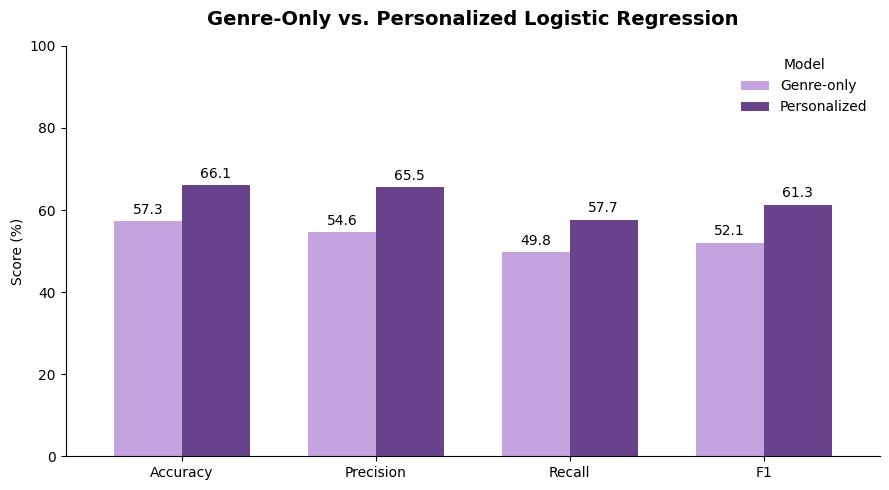

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import matplotlib.pyplot as plt
from google.colab import files

# Consistent report color palette
DARK_PURPLE = "#68438C"
LILAC = "#C5A3E0"

metrics = comparison_df.set_index("Metric")[
    ["Genre-only", "Personalized"]
] * 100

fig, ax = plt.subplots(figsize=(9, 5))

metrics.plot(
    kind="bar",
    ax=ax,
    color=[LILAC, DARK_PURPLE],
    width=0.7
)

ax.set_title(
    "Genre-Only vs. Personalized Logistic Regression",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Score (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.legend(title="Model", frameon=False)
ax.tick_params(axis="x", rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save the report-ready figure
filename = "model_comparison_metrics.png"
fig.savefig(filename, dpi=300, bbox_inches="tight")

plt.show()

# Download the figure
files.download(filename)

### Visualization: Confusion Matrix Comparison

Compare true negatives, false positives, false negatives, and true positives for both models. Identify how personalization changes classification errors on the same held-out test set.

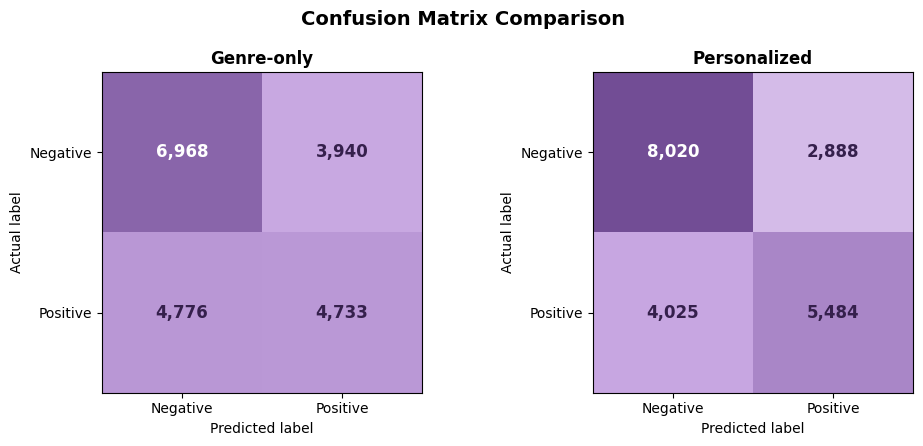

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from google.colab import files

baseline_cm = np.array([[6968, 3940], [4776, 4733]])

purple_cmap = LinearSegmentedColormap.from_list(
    "purple_lilac", ["#F5EFFA", "#C5A3E0", "#68438C"]
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, cm, title in zip(
    axes,
    [baseline_cm, personalized_cm],
    ["Genre-only", "Personalized"]
):
    ax.imshow(cm, cmap=purple_cmap, vmin=0, vmax=8500)

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center",
                color="white" if cm[i, j] > 6000 else "#35204C",
                fontsize=12, fontweight="bold"
            )

    ax.set_xticks([0, 1], ["Negative", "Positive"])
    ax.set_yticks([0, 1], ["Negative", "Positive"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_title(title, fontweight="bold")

fig.suptitle(
    "Confusion Matrix Comparison",
    fontsize=14, fontweight="bold"
)

plt.tight_layout()

filename = "confusion_matrix_comparison.png"
fig.savefig(filename, dpi=300, bbox_inches="tight")
plt.show()

files.download(filename)

## Model Interpretability

Examine the learned Logistic Regression coefficients to understand how movie genres and user-history features influence predicted positive preferences.

Positive coefficients increase predicted log-odds, while negative coefficients decrease them, holding other inputs constant. Coefficients indicate associations rather than causal effects.

In [37]:
coefficient_df = pd.DataFrame({
    "Feature": personalized_features,
    "Coefficient": personalized_model.coef_[0]
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(coefficient_df)

,Feature,Coefficient,Absolute Coefficient
21,prior_mean_rating,0.717825,0.717825
7,Documentary,0.648811,0.648811
3,Animation,0.522255,0.522255
10,Film-Noir,0.459682,0.459682
4,Children,-0.454851,0.454851
18,War,0.427983,0.427983
6,Crime,0.319212,0.319212
1,Action,-0.305264,0.305264
8,Drama,0.299433,0.299433
5,Comedy,-0.241305,0.241305


### Visualization: Personalized Feature Coefficients

Visualize the direction and magnitude of the two standardized user-history coefficients. Interpret their associations with predicted positive preference while acknowledging that coefficients do not establish causality.

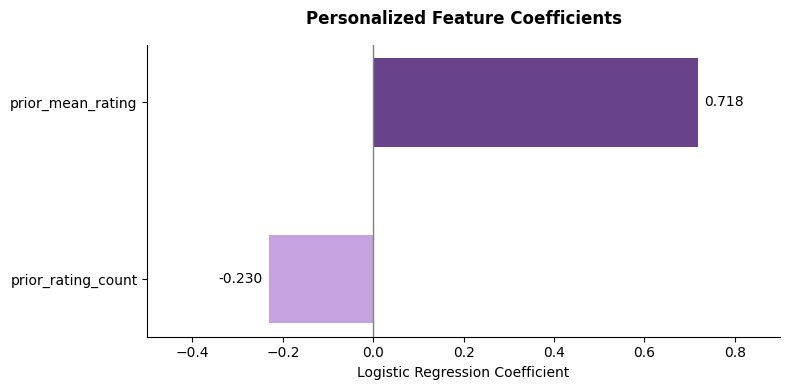

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
history_coefs = coefficient_df[
    coefficient_df["Feature"].isin(history_features)
].set_index("Feature").loc[history_features]

fig, ax = plt.subplots(figsize=(8, 4))

colors = [
    "#68438C" if value > 0 else "#C5A3E0"
    for value in history_coefs["Coefficient"]
]

bars = ax.barh(
    history_coefs.index,
    history_coefs["Coefficient"],
    color=colors,
    height=0.5
)

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Logistic Regression Coefficient")
ax.set_title(
    "Personalized Feature Coefficients",
    fontweight="bold",
    pad=15
)

ax.bar_label(bars, fmt="%.3f", padding=5)
ax.set_xlim(-0.5, 0.9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

filename = "personalized_feature_coefficients.png"
fig.savefig(filename, dpi=300, bbox_inches="tight")
plt.show()

files.download(filename)

## Fair Comparison and Reproducibility

Verify that the genre-only baseline and personalized model use identical held-out test interactions. Load the saved baseline predictions and check their consistency with the current test dataset before finalizing performance comparisons.

In [40]:
# Locate the saved baseline predictions archive
baseline_zip_files = [
    project_root / "results" / "metrics" / "baseline_results.zip"
]

print("Matching baseline archives:", len(baseline_zip_files))

for path in baseline_zip_files:
    print(path)

Matching baseline archives: 1
/content/drive/MyDrive/Colab Notebooks/streaming-recommendation-system/results/metrics/baseline_results.zip


In [41]:
#verify the saved files

baseline_zip_path = baseline_zip_files[0]

with ZipFile(baseline_zip_path, "r") as zip_ref:
    baseline_files = zip_ref.namelist()

print("Files inside baseline archive:")

for filename in baseline_files:
    print("-", filename)

Files inside baseline archive:
- baseline_metrics.csv
- genre_coefficients.csv
- baseline_test_predictions.csv


In [42]:
#load the saved predictions

with ZipFile(baseline_zip_path, "r") as zip_ref:
    baseline_predictions = pd.read_csv(
        zip_ref.open("baseline_test_predictions.csv")
    )

print("Baseline predictions shape:", baseline_predictions.shape)

print("\nColumns:")
print(baseline_predictions.columns.tolist())

print("\nFirst five rows:")
display(baseline_predictions.head())

Baseline predictions shape: (20417, 6)

Columns:
['userId', 'movieId', 'timestamp', 'positive_rating', 'predicted_target', 'positive_probability']

First five rows:


,userId,movieId,timestamp,positive_rating,predicted_target,positive_probability
0,1,2959,964983282,1,1,0.543825
1,1,1219,964983393,0,0,0.484926
2,1,1348,964983393,1,0,0.397078
3,1,2644,964983393,1,0,0.397078
4,1,2654,964983393,1,0,0.492482


In [43]:
# Columns that uniquely describe the evaluation records
comparison_columns = [
    "userId",
    "movieId",
    "timestamp",
    "positive_rating"
]

# Compare baseline records with the current held-out test set
pd.testing.assert_frame_equal(
    baseline_predictions[comparison_columns].reset_index(drop=True),
    test_personalized[comparison_columns].reset_index(drop=True),
    check_dtype=False
)

print("Baseline and personalized test rows match!")
print("Verified interactions:", len(baseline_predictions))

Baseline and personalized test rows match!
Verified interactions: 20417


In [44]:
#recalculate baseline metrics

baseline_y_true = baseline_predictions["positive_rating"]
baseline_y_pred = baseline_predictions["predicted_target"]

verified_baseline_metrics = {
    "Accuracy": accuracy_score(baseline_y_true, baseline_y_pred),
    "Precision": precision_score(baseline_y_true, baseline_y_pred),
    "Recall": recall_score(baseline_y_true, baseline_y_pred),
    "F1": f1_score(baseline_y_true, baseline_y_pred)
}

print("Verified baseline metrics:")

for metric, value in verified_baseline_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nVerified baseline confusion matrix:")
print(confusion_matrix(
    baseline_y_true,
    baseline_y_pred,
    labels=[0, 1]
))

Verified baseline metrics:
Accuracy: 0.573101
Precision: 0.545717
Recall: 0.497739
F1: 0.520625

Verified baseline confusion matrix:
[[6968 3940]
 [4776 4733]]


In [45]:
#update the comparison table

# Replace manually recorded baseline values with verified metrics
for metric, value in verified_baseline_metrics.items():
    comparison_df.loc[
        comparison_df["Metric"] == metric,
        "Genre-only"
    ] = value

# Recalculate improvements using verified values
comparison_df["Improvement (pp)"] = (
    comparison_df["Personalized"] -
    comparison_df["Genre-only"]
) * 100

display(comparison_df.round(4))

,Metric,Genre-only,Personalized,Improvement (pp)
0,Accuracy,0.5731,0.6614,8.8309
1,Precision,0.5457,0.6550,10.9324
2,Recall,0.4977,0.5767,7.8978
3,F1,0.5206,0.6134,9.2764


## Model Export and Reproducibility

Save the trained personalized Logistic Regression model, fitted feature scaler, and input feature definitions. These artifacts preserve the model's learned parameters and preprocessing configuration for future inference and application integration.

In [46]:
import joblib
from google.colab import files

model_artifacts = {
    "model": personalized_model,
    "scaler": scaler,
    "genre_features": genre_features,
    "history_features": history_features,
    "personalized_features": personalized_features,
    "cold_start_fallback": cold_start_fallback,
    "decision_threshold": 0.5
}

filename = "personalized_model_bundle.joblib"

joblib.dump(model_artifacts, filename)

print("Model artifacts saved:", filename)

files.download(filename)

Model artifacts saved: personalized_model_bundle.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
# Reload the saved model bundle
loaded_artifacts = joblib.load(filename)

loaded_model = loaded_artifacts["model"]
loaded_scaler = loaded_artifacts["scaler"]

# Recreate test inputs using the saved preprocessing
X_test_reloaded = X_test.copy()

X_test_reloaded[history_features] = loaded_scaler.transform(
    X_test[history_features]
)

# Generate predictions using the reloaded model
reloaded_predictions = loaded_model.predict(X_test_reloaded)

# Verify that predictions match the original model
import numpy as np

assert np.array_equal(
    reloaded_predictions,
    y_pred_personalized
), "Reloaded model predictions do not match!"

print("Model reload validation passed!")
print("Matching predictions:", len(reloaded_predictions))

Model reload validation passed!
Matching predictions: 20417


In [48]:
# Export the fixed training-history snapshot
snapshot_filename = "user_history_snapshot.csv"

user_history_snapshot.to_csv(
    snapshot_filename,
    index=False
)

print("Snapshot saved:", snapshot_filename)
print("Users exported:", len(user_history_snapshot))

# Verify the exported CSV
snapshot_check = pd.read_csv(snapshot_filename)

pd.testing.assert_frame_equal(
    snapshot_check,
    user_history_snapshot,
    check_dtype=False,
    check_exact=False,
    rtol=1e-10
)

print("Snapshot export validation passed!")

files.download(snapshot_filename)

Snapshot saved: user_history_snapshot.csv
Users exported: 610
Snapshot export validation passed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Export Personalized Predictions

Save the personalized model's predictions and positive-class probabilities for all held-out test interactions. Preserve interaction identifiers and actual labels to support reproducible evaluation, error analysis, and comparison with the genre-only baseline.

In [49]:
# Create the personalized predictions table
personalized_predictions = test_personalized[
    ["userId", "movieId", "timestamp", "positive_rating"]
].copy()

personalized_predictions["predicted_target"] = y_pred_personalized
personalized_predictions["positive_probability"] = y_prob_personalized

# Validate the exported predictions
assert len(personalized_predictions) == 20417
assert personalized_predictions["positive_probability"].between(0, 1).all()
assert personalized_predictions["predicted_target"].isin([0, 1]).all()

# Export and download
predictions_filename = "personalized_test_predictions.csv"

personalized_predictions.to_csv(
    predictions_filename,
    index=False
)

print("Predictions saved:", predictions_filename)
print("Interactions exported:", len(personalized_predictions))

display(personalized_predictions.head())

files.download(predictions_filename)

Predictions saved: personalized_test_predictions.csv
Interactions exported: 20417


,userId,movieId,timestamp,positive_rating,predicted_target,positive_probability
0,1,2959,964983282,1,1,0.782360
1,1,1219,964983393,0,1,0.771821
2,1,1348,964983393,1,1,0.710829
3,1,2644,964983393,1,1,0.710829
4,1,2654,964983393,1,1,0.770148


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Export Evaluation Results

Save the verified baseline-versus-personalized performance comparison as a CSV file. Preserve full numerical precision for reproducibility and future technical reporting.

In [50]:
# Export the verified model comparison
metrics_filename = "model_comparison_metrics.csv"

comparison_df.to_csv(
    metrics_filename,
    index=False
)

# Reload to verify the saved values
metrics_check = pd.read_csv(metrics_filename)

pd.testing.assert_frame_equal(
    metrics_check,
    comparison_df,
    check_exact=False,
    rtol=1e-10
)

print("Evaluation metrics exported successfully!")
print("File:", metrics_filename)
print("Metrics:", len(metrics_check))

display(metrics_check.round(4))

files.download(metrics_filename)

Evaluation metrics exported successfully!
File: model_comparison_metrics.csv
Metrics: 4


,Metric,Genre-only,Personalized,Improvement (pp)
0,Accuracy,0.5731,0.6614,8.8309
1,Precision,0.5457,0.6550,10.9324
2,Recall,0.4977,0.5767,7.8978
3,F1,0.5206,0.6134,9.2764


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Experimental Limitations

**1. Timestamp resolution:** The chronological train/test split contains 130 users with equal timestamps at the split boundary. Within training, interactions sharing a timestamp were treated as simultaneous. Test features use a fixed training-history snapshot, so strict ordering cannot be guaranteed for boundary ties.

**2. Fixed test-history snapshot:** Test features use only training ratings and are not updated using test interactions. This supports a consistent offline comparison but does not simulate a continuously updating recommendation system.

**3. Cold-start fallback:** Training interactions without prior user history use a fixed neutral prior mean of 2.75. This avoids target leakage but may not be the optimal fallback. The evaluation does not independently establish performance for completely new users.

**4. Limited personalization:** The model uses only prior rating count and mean rating. It does not yet represent individual genre preferences, collaborative relationships, or changes in user interests over time.

**5. Classification versus recommendation:** Accuracy, precision, recall, and F1 evaluate positive-rating classification, not the quality of a ranked recommendation list. Recommendation-specific evaluation remains future work.

**6. Model selection and generalization:** The reported comparison uses the held-out test set. Further feature selection, hyperparameter tuning, or algorithm selection should use training-side temporal validation rather than repeatedly optimizing against test results.

**7. Feature availability:** The offline evaluation assumes historical ratings are available when generating predictions. A deployed system must ensure that the same information is available at inference time and that preprocessing remains consistent.

## Summary and Key Findings

### Work Completed

- Constructed two personalized features: prior rating count and prior mean rating.
- Prevented training-history leakage by excluding the current timestamp group and all later interactions.
- Applied a fixed training-history snapshot to held-out test interactions without incorporating test ratings.
- Validated feature calculations, cold-start handling, dataset integrity, and baseline test-row alignment.
- Trained and evaluated a personalized Logistic Regression model using 22 features.
- Saved the trained model, fitted scaler, user-history snapshot, test predictions, and evaluation results.

### Model Comparison

| Metric | Genre-only | Personalized | Improvement |
|---|---:|---:|---:|
| Accuracy | 57.31% | 66.14% | +8.83 pp |
| Precision | 54.57% | 65.50% | +10.93 pp |
| Recall | 49.77% | 57.67% | +7.90 pp |
| F1 | 52.06% | 61.34% | +9.28 pp |

### Key Findings

Adding prior rating count and prior mean rating improved all four classification metrics on the same 20,417 held-out interactions. Prior mean rating had a positive Logistic Regression coefficient (+0.718), while prior rating count had a negative coefficient (-0.230). These coefficients describe conditional associations rather than causal relationships.

The results support the hypothesis that user-history information can improve positive-preference prediction beyond movie genres alone, subject to the documented temporal and evaluation limitations.

### Next Steps

- Conduct deeper evaluation by user-history length and investigate prediction errors.
- Explore Random Forest and XGBoost using training-side temporal validation.
- Evaluate ranked recommendation quality.
- Integrate the selected model into an interactive movie recommendation application.

**Conclusion:** Personalized history features improved positive-rating classification performance and provide a foundation for further evaluation and system integration.